In [158]:
from dotenv import load_dotenv
load_dotenv()

True

In [159]:
from langgraph.graph import START,END ,StateGraph
from langchain_groq import ChatGroq
from serpapi_search_tools import news_search,web_search
from pydantic import BaseModel,Field
from typing import Literal,Annotated
from langchain.tools import tool
from langchain.agents import create_agent
from langchain_community.utilities import OpenWeatherMapAPIWrapper


In [160]:
llm=ChatGroq(model="openai/gpt-oss-20b")

In [161]:
class schema_state(BaseModel):
    question:str=Field(description="User asked question")
    que_cat:Literal["coding","google","weather"]=Field(description="These are the question categories taken currently",default="google")
    answer:str=Field(description="Answer to the user asked question",default="")

In [162]:
class question_category(BaseModel):
    que_cat:Literal["coding","google","weather"]=Field(description="These are the question categories taken currently")


In [163]:
def check_que_cat(state:schema_state)->schema_state:
    llm_struct=llm.with_structured_output(question_category)
    res=llm_struct.invoke(f"Tell me the category of the question:{state.question} , if you dont know give it as 'google' ")
    state.que_cat=res.que_cat
    return state


In [164]:
def route(state:schema_state)->Literal["coding","weather","google"]:
    return state.que_cat

In [165]:
google_agent=create_agent(
    model=llm,
    tools=[news_search(),web_search()],
    system_prompt="You are an google search agent which uses tools to search on google"
)

In [166]:
weather_api=OpenWeatherMapAPIWrapper()

In [167]:
weather_agent=create_agent(
    model=llm,
    tools=[weather_api.run],
    system_prompt="You are an helpful weather agent which tells the temperature of give location , do not invent the weather details"
)

In [168]:
def google(state:schema_state)->schema_state:
    res=google_agent.invoke({"messages":[{"role":"user","content":state.question}]})
    state.answer=res["messages"][-1].content
    return state


In [169]:
def coding(state:schema_state)->schema_state:
    res=llm.invoke(state.question)
    state.answer=res.content
    return state

In [170]:
def weather(state:schema_state)->schema_state:
    res=weather_agent.invoke({"messages":[{"role":"user","content":state.question}]})
    state.answer=res["messages"][-1].content
    return state


In [171]:
graph=StateGraph(schema_state)

In [172]:
graph.add_node("que_cat",check_que_cat)

In [173]:
graph.add_edge(START,"que_cat")

In [174]:
graph.add_conditional_edges(
    "que_cat",
    route
)

In [175]:
graph.add_node("google",google)

In [176]:
graph.add_node("weather",weather)

In [177]:
graph.add_node("coding",coding)

In [178]:
graph.add_edge("weather",END)
graph.add_edge("coding",END)
graph.add_edge("google",END)

In [179]:
finalgraph=graph.compile()

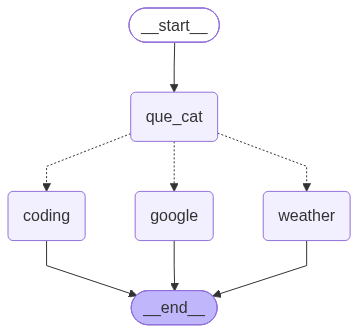

In [180]:
from IPython.display import Image
Image(finalgraph.get_graph().draw_mermaid_png())

In [184]:
finalgraph.invoke({"question":"what is the temperature in Finland's capital"})

{'question': "what is the temperature in Finland's capital",
 'que_cat': 'weather',
 'answer': 'The current temperature in Helsinki is **10.35\u202f°C**.'}